# Dose Response Fitting

Experimental L858R EGFR phosphosite IC50s:
Y845 : 13.00 nM
Y992 : 18.00 nM
Y1045: 8.00 nM
Y1068: 54.00 nM
Y1148: 16.00 nM
Y1173: 10.00 nM

Effective EGFR IC50 (geometric mean): 15.90 nM
Experimental pERK IC50: 19.0 ± 9.0 nM

No-drug steady state
--------------------
EGFR* = 0.666667
ERK*  = 0.507937
P     = 2.031746

MODEL IC50 RESULTS
------------------
Model EGFR* IC50: 47.686 nM
Model ERK* IC50:  1011.638 nM
Model P IC50:     1011.638 nM

EXPERIMENTAL COMPARISON
-----------------------
Experimental EGFR effective IC50: 15.903 nM
Experimental pERK IC50: 19.0 ± 9.0 nM

MODEL–EXPERIMENT MISMATCH
-------------------------
ERK IC50 ratio (model / experiment): 53.24x
Absolute difference: 992.64 nM


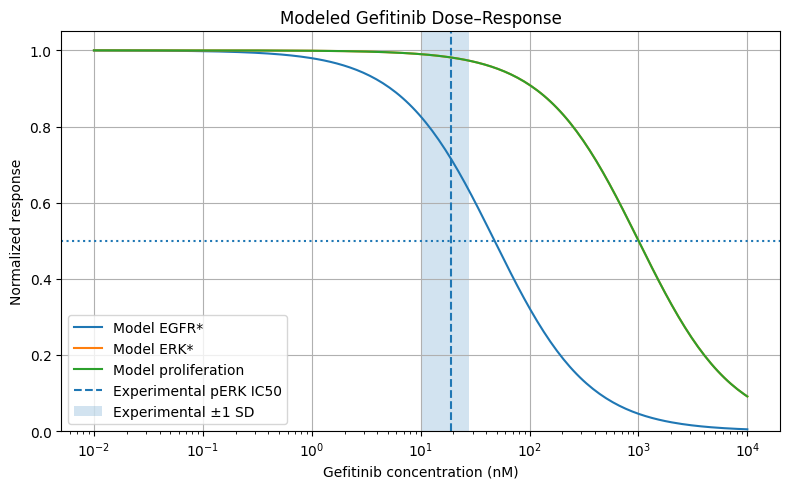

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar


# ============================================================
# 1. EXPERIMENTAL DATA — Kim et al. 2015
# ============================================================

# L858R EGFR phosphosite gefitinib IC50 values
# Units: nM

sites = np.array([
    "Y845",
    "Y992",
    "Y1045",
    "Y1068",
    "Y1148",
    "Y1173"
])

EGFR_IC50_exp = np.array([
    13.0,
    18.0,
    8.0,
    54.0,
    16.0,
    10.0
])

# Experimental downstream pERK IC50
pERK_IC50_exp = 19.0
pERK_IC50_sd = 9.0


# ============================================================
# 2. EFFECTIVE EGFR IC50
# ============================================================

# IC50 values span an order of magnitude, so use geometric mean
# rather than arithmetic mean.

EGFR_IC50_eff = np.exp(np.mean(np.log(EGFR_IC50_exp)))

print("Experimental L858R EGFR phosphosite IC50s:")
for site, ic50 in zip(sites, EGFR_IC50_exp):
    print(f"{site:5s}: {ic50:.2f} nM")

print()
print(f"Effective EGFR IC50 (geometric mean): "
      f"{EGFR_IC50_eff:.2f} nM")

print(f"Experimental pERK IC50: "
      f"{pERK_IC50_exp:.1f} ± {pERK_IC50_sd:.1f} nM")


# ============================================================
# 3. MODEL PARAMETERS
# ============================================================

params = {

    "EGF": 1.0,

    # This will initially be set to the experimentally
    # constrained effective EGFR IC50.
    "IC_50": EGFR_IC50_eff,

    # Cannot be fitted from IC50 data alone.
    # Keep the original model value for now.
    "n": 1.0,

    "k_EGF": 1.0,
    "k_EGFR_off": 0.5,

    "k_RAS": 1.0,
    "k_RAS_off": 0.5,

    "k_RAF": 1.0,
    "k_RAF_off": 0.5,

    "k_MEK": 1.0,
    "k_MEK_off": 0.5,

    "k_ERK": 1.0,
    "k_ERK_off": 0.5,

    "k_T": 1.0,
    "k_deg": 0.5,

    "k_P": 1.0,
    "k_loss": 0.5,
}


# ============================================================
# 4. YOUR ORIGINAL ODE MODEL
# ============================================================

y0 = np.zeros(7)

T_steady = 80.0


def pathway(t, y, params, G):

    EGF = params["EGF"]
    IC_50 = params["IC_50"]
    n = params["n"]

    EGFR_star, RAS_star, RAF_star, MEK_star, ERK_star, CycD, P = y

    # Total normalized protein pools
    EGFR_tot = 1.0
    RAS_tot = 1.0
    RAF_tot = 1.0
    MEK_tot = 1.0
    ERK_tot = 1.0

    # Rate constants
    k_EGF = params["k_EGF"]
    k_EGFR_off = params["k_EGFR_off"]

    k_RAS = params["k_RAS"]
    k_RAS_off = params["k_RAS_off"]

    k_RAF = params["k_RAF"]
    k_RAF_off = params["k_RAF_off"]

    k_MEK = params["k_MEK"]
    k_MEK_off = params["k_MEK_off"]

    k_ERK = params["k_ERK"]
    k_ERK_off = params["k_ERK_off"]

    k_T = params["k_T"]
    k_deg = params["k_deg"]

    k_P = params["k_P"]
    k_loss = params["k_loss"]


    # --------------------------------------------------------
    # EGFR inhibition by gefitinib
    # --------------------------------------------------------

    EGFR_gefit = 1.0 / (
        1.0 + (G / IC_50)**n
    )

    EGFR_act = (
        k_EGF
        * EGF
        * (EGFR_tot - EGFR_star)
        * EGFR_gefit
    )

    EGFR_dect = k_EGFR_off * EGFR_star

    dEGFR = EGFR_act - EGFR_dect


    # --------------------------------------------------------
    # RAS
    # --------------------------------------------------------

    RAS_act = (
        k_RAS
        * EGFR_star
        * (RAS_tot - RAS_star)
    )

    RAS_dect = k_RAS_off * RAS_star

    dRAS = RAS_act - RAS_dect


    # --------------------------------------------------------
    # RAF
    # --------------------------------------------------------

    RAF_act = (
        k_RAF
        * RAS_star
        * (RAF_tot - RAF_star)
    )

    RAF_dect = k_RAF_off * RAF_star

    dRAF = RAF_act - RAF_dect


    # --------------------------------------------------------
    # MEK
    # --------------------------------------------------------

    MEK_act = (
        k_MEK
        * RAF_star
        * (MEK_tot - MEK_star)
    )

    MEK_dect = k_MEK_off * MEK_star

    dMEK = MEK_act - MEK_dect


    # --------------------------------------------------------
    # ERK
    # --------------------------------------------------------

    ERK_act = (
        k_ERK
        * MEK_star
        * (ERK_tot - ERK_star)
    )

    ERK_dect = k_ERK_off * ERK_star

    dERK = ERK_act - ERK_dect


    # --------------------------------------------------------
    # Cyclin D
    # --------------------------------------------------------

    CycD_act = k_T * ERK_star
    CycD_dect = k_deg * CycD

    dCycD = CycD_act - CycD_dect


    # --------------------------------------------------------
    # Proliferation
    # --------------------------------------------------------

    P_act = k_P * CycD
    P_dect = k_loss * P

    dP = P_act - P_dect


    return [
        dEGFR,
        dRAS,
        dRAF,
        dMEK,
        dERK,
        dCycD,
        dP
    ]


# ============================================================
# 5. FUNCTION TO GET STEADY-STATE RESPONSE
# ============================================================

def get_steady_state(G, params):

    solution = solve_ivp(
        pathway,
        [0, T_steady],
        y0,
        args=(params, G),
        rtol=1e-9,
        atol=1e-12
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    return solution.y[:, -1]


# ============================================================
# 6. CALCULATE NO-DRUG BASELINE
# ============================================================

baseline = get_steady_state(0.0, params)

EGFR_baseline = baseline[0]
ERK_baseline = baseline[4]
P_baseline = baseline[6]

print()
print("No-drug steady state")
print("--------------------")
print(f"EGFR* = {EGFR_baseline:.6f}")
print(f"ERK*  = {ERK_baseline:.6f}")
print(f"P     = {P_baseline:.6f}")


# ============================================================
# 7. GENERATE MODEL DOSE-RESPONSE
# ============================================================

# nM
G_conc = np.logspace(-2, 4, 200)

EGFR_response = []
ERK_response = []
P_response = []

for G in G_conc:

    ss = get_steady_state(G, params)

    EGFR_response.append(ss[0])
    ERK_response.append(ss[4])
    P_response.append(ss[6])


EGFR_response = np.array(EGFR_response)
ERK_response = np.array(ERK_response)
P_response = np.array(P_response)


# Normalize to no-drug response
EGFR_norm = EGFR_response / EGFR_baseline
ERK_norm = ERK_response / ERK_baseline
P_norm = P_response / P_baseline


# ============================================================
# 8. FIND MODEL IC50
# ============================================================

def find_ic50(concentrations, response):

    # We want response = 0.5
    difference = np.abs(response - 0.5)

    index = np.argmin(difference)

    return concentrations[index]


model_EGFR_IC50 = find_ic50(
    G_conc,
    EGFR_norm
)

model_ERK_IC50 = find_ic50(
    G_conc,
    ERK_norm
)

model_P_IC50 = find_ic50(
    G_conc,
    P_norm
)


print()
print("MODEL IC50 RESULTS")
print("------------------")
print(f"Model EGFR* IC50: {model_EGFR_IC50:.3f} nM")
print(f"Model ERK* IC50:  {model_ERK_IC50:.3f} nM")
print(f"Model P IC50:     {model_P_IC50:.3f} nM")

print()
print("EXPERIMENTAL COMPARISON")
print("-----------------------")
print(f"Experimental EGFR effective IC50: "
      f"{EGFR_IC50_eff:.3f} nM")

print(f"Experimental pERK IC50: "
      f"{pERK_IC50_exp:.1f} ± {pERK_IC50_sd:.1f} nM")


# ============================================================
# 9. CALCULATE MISMATCH
# ============================================================

ERK_IC50_ratio = model_ERK_IC50 / pERK_IC50_exp

print()
print("MODEL–EXPERIMENT MISMATCH")
print("-------------------------")
print(f"ERK IC50 ratio (model / experiment): "
      f"{ERK_IC50_ratio:.2f}x")

print(f"Absolute difference: "
      f"{abs(model_ERK_IC50 - pERK_IC50_exp):.2f} nM")


# ============================================================
# 10. PLOT DOSE-RESPONSE
# ============================================================

plt.figure(figsize=(8, 5))

plt.semilogx(
    G_conc,
    EGFR_norm,
    label="Model EGFR*"
)

plt.semilogx(
    G_conc,
    ERK_norm,
    label="Model ERK*"
)

plt.semilogx(
    G_conc,
    P_norm,
    label="Model proliferation"
)

# Experimental pERK IC50
plt.axvline(
    pERK_IC50_exp,
    linestyle="--",
    label="Experimental pERK IC50"
)

# Experimental uncertainty
plt.axvspan(
    pERK_IC50_exp - pERK_IC50_sd,
    pERK_IC50_exp + pERK_IC50_sd,
    alpha=0.2,
    label="Experimental ±1 SD"
)

plt.axhline(
    0.5,
    linestyle=":"
)

plt.xlabel("Gefitinib concentration (nM)")
plt.ylabel("Normalized response")
plt.title("Modeled Gefitinib Dose–Response")

plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [3]:
# ============================================================
# DIAGNOSTIC: WHICH DOWNSTREAM NODE CONTROLS ERK IC50?
# ============================================================

def calculate_ERK_IC50(params):

    baseline = get_steady_state(0.0, params)
    ERK_baseline = baseline[4]

    G_test = np.logspace(-2, 4, 250)
    ERK_response = []

    for G in G_test:
        ss = get_steady_state(G, params)
        ERK_response.append(ss[4])

    ERK_response = np.array(ERK_response)
    ERK_norm = ERK_response / ERK_baseline

    index = np.argmin(np.abs(ERK_norm - 0.5))

    return G_test[index]


# ------------------------------------------------------------
# Test each downstream activation rate
# ------------------------------------------------------------

parameters_to_test = [
    "k_RAS",
    "k_RAF",
    "k_MEK",
    "k_ERK"
]

test_values = np.logspace(-2, 2, 15)

results = {}

for parameter in parameters_to_test:

    ic50_values = []

    for value in test_values:

        test_params = params.copy()
        test_params[parameter] = value

        ic50 = calculate_ERK_IC50(test_params)

        ic50_values.append(ic50)

    results[parameter] = np.array(ic50_values)


# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("\nDOWNSTREAM PARAMETER SENSITIVITY")
print("=" * 70)

for parameter in parameters_to_test:

    print(f"\n{parameter}")

    for value, ic50 in zip(
        test_values,
        results[parameter]
    ):

        print(
            f"{value:10.4f}  ->  "
            f"ERK IC50 = {ic50:10.3f} nM"
        )


DOWNSTREAM PARAMETER SENSITIVITY

k_RAS
    0.0100  ->  ERK IC50 =     57.416 nM
    0.0193  ->  ERK IC50 =     67.815 nM
    0.0373  ->  ERK IC50 =     84.666 nM
    0.0720  ->  ERK IC50 =    118.111 nM
    0.1389  ->  ERK IC50 =    184.103 nM
    0.2683  ->  ERK IC50 =    303.339 nM
    0.5179  ->  ERK IC50 =    528.313 nM
    1.0000  ->  ERK IC50 =   1028.130 nM
    1.9307  ->  ERK IC50 =   1892.816 nM
    3.7276  ->  ERK IC50 =   3683.537 nM
    7.1969  ->  ERK IC50 =   6781.493 nM
   13.8950  ->  ERK IC50 =  10000.000 nM
   26.8270  ->  ERK IC50 =  10000.000 nM
   51.7947  ->  ERK IC50 =  10000.000 nM
  100.0000  ->  ERK IC50 =  10000.000 nM

k_RAF
    0.0100  ->  ERK IC50 =    118.111 nM
    0.0193  ->  ERK IC50 =    131.972 nM
    0.0373  ->  ERK IC50 =    147.460 nM
    0.0720  ->  ERK IC50 =    174.166 nM
    0.1389  ->  ERK IC50 =    229.851 nM
    0.2683  ->  ERK IC50 =    358.275 nM
    0.5179  ->  ERK IC50 =    558.455 nM
    1.0000  ->  ERK IC50 =   1028.130 nM
    1.930

In [4]:
# ============================================================
# DEACTIVATION-RATE SENSITIVITY
# ============================================================

parameters_to_test = [
    "k_RAS_off",
    "k_RAF_off",
    "k_MEK_off",
    "k_ERK_off"
]

test_values = np.logspace(-2, 2, 15)

results_off = {}

for parameter in parameters_to_test:

    ic50_values = []

    for value in test_values:

        test_params = params.copy()
        test_params[parameter] = value

        ic50 = calculate_ERK_IC50(test_params)

        ic50_values.append(ic50)

    results_off[parameter] = np.array(ic50_values)


print("\nDOWNSTREAM DEACTIVATION SENSITIVITY")
print("=" * 70)

for parameter in parameters_to_test:

    print(f"\n{parameter}")

    for value, ic50 in zip(
        test_values,
        results_off[parameter]
    ):

        print(
            f"{value:10.4f}  ->  "
            f"ERK IC50 = {ic50:10.3f} nM"
        )


DOWNSTREAM DEACTIVATION SENSITIVITY

k_RAS_off
    0.0100  ->  ERK IC50 =  10000.000 nM
    0.0193  ->  ERK IC50 =  10000.000 nM
    0.0373  ->  ERK IC50 =  10000.000 nM
    0.0720  ->  ERK IC50 =   6781.493 nM
    0.1389  ->  ERK IC50 =   3484.726 nM
    0.2683  ->  ERK IC50 =   1790.656 nM
    0.5179  ->  ERK IC50 =    972.639 nM
    1.0000  ->  ERK IC50 =    528.313 nM
    1.9307  ->  ERK IC50 =    286.967 nM
    3.7276  ->  ERK IC50 =    174.166 nM
    7.1969  ->  ERK IC50 =    111.736 nM
   13.8950  ->  ERK IC50 =     80.097 nM
   26.8270  ->  ERK IC50 =     64.155 nM
   51.7947  ->  ERK IC50 =     57.416 nM
  100.0000  ->  ERK IC50 =     51.386 nM

k_RAF_off
    0.0100  ->  ERK IC50 =  10000.000 nM
    0.0193  ->  ERK IC50 =  10000.000 nM
    0.0373  ->  ERK IC50 =  10000.000 nM
    0.0720  ->  ERK IC50 =   6415.476 nM
    0.1389  ->  ERK IC50 =   3296.646 nM
    0.2683  ->  ERK IC50 =   1790.656 nM
    0.5179  ->  ERK IC50 =    972.639 nM
    1.0000  ->  ERK IC50 =    558.455 n

In [ ]:
# ============================================================
# GLOBAL FIT: DOWNSTREAM STEADY-STATE SENSITIVITY
# ============================================================

from scipy.optimize import minimize
import numpy as np

# ------------------------------------------------------------
# Experimental target
# ------------------------------------------------------------

TARGET_IC50 = 19.0       # nM
TARGET_SD = 9.0          # nM


# ------------------------------------------------------------
# Faster steady-state calculation
# ------------------------------------------------------------

def get_ERK_response(G, p):

    ss = get_steady_state(G, p)

    return ss[4]


# ------------------------------------------------------------
# More accurate IC50 calculation
# ------------------------------------------------------------

from scipy.optimize import brentq


def calculate_ERK_IC50_precise(p):

    # No-drug ERK
    ERK0 = get_ERK_response(0.0, p)

    # Guard against invalid no-drug response
    if not np.isfinite(ERK0) or ERK0 <= 0:
        return np.nan

    def response_difference(logG):

        G = 10 ** logG
        ERK = get_ERK_response(G, p)

        # Guard against invalid model output
        if not np.isfinite(ERK):
            return np.nan

        normalized = ERK / ERK0

        return normalized - 0.5

    logG_low = -3
    logG_high = 6

    f_low = response_difference(logG_low)
    f_high = response_difference(logG_high)

    # Guard against NaNs
    if not np.isfinite(f_low) or not np.isfinite(f_high):
        return np.nan

    # Response must cross 50%
    if f_low * f_high > 0:
        return np.nan

    root = brentq(
        response_difference,
        logG_low,
        logG_high
    )

    return 10 ** root


# ============================================================
# PARAMETERIZATION
# ============================================================

# Instead of fitting k_act and k_off independently,
# fit their ratios.
#
# We keep k_off = 0.5 and alter k_act.
#
# This preserves the original time scale while allowing
# equilibrium sensitivity to change.

def make_params_from_ratios(log_ratios):

    p = params.copy()

    ratios = 10 ** np.array(log_ratios)

    p["k_RAS"] = ratios[0] * p["k_RAS_off"]
    p["k_RAF"] = ratios[1] * p["k_RAF_off"]
    p["k_MEK"] = ratios[2] * p["k_MEK_off"]
    p["k_ERK"] = ratios[3] * p["k_ERK_off"]

    return p


# ============================================================
# OBJECTIVE FUNCTION
# ============================================================

def objective(log_ratios):

    p = make_params_from_ratios(log_ratios)

    ic50 = calculate_ERK_IC50_precise(p)

    # Penalize parameter sets that don't produce an IC50
    if np.isnan(ic50):
        return 1e6

    # Fit in log space because IC50 spans orders of magnitude
    error = np.log10(ic50 / TARGET_IC50)

    return error ** 2


# ============================================================
# INITIAL CONDITION
# ============================================================

# Current model:
#
# k_RAS / k_RAS_off = 2
# k_RAF / k_RAF_off = 2
# k_MEK / k_MEK_off = 2
# k_ERK / k_ERK_off = 2

initial_ratios = np.log10([
    2.0,
    2.0,
    2.0,
    2.0
])


# ============================================================
# GLOBAL OPTIMIZATION
# ============================================================

result = minimize(
    objective,
    initial_ratios,
    method="Nelder-Mead",
    options={
        "maxiter": 1000,
        "xatol": 1e-5,
        "fatol": 1e-8
    }
)


# ============================================================
# RESULTS
# ============================================================

best_params = make_params_from_ratios(result.x)

best_ratios = 10 ** result.x

best_IC50 = calculate_ERK_IC50_precise(best_params)


print("\nGLOBAL DOWNSTREAM FIT")
print("=" * 60)

print(f"Optimization success: {result.success}")
print(f"Message: {result.message}")

print("\nBest downstream activation/deactivation ratios:")

print(
    f"k_RAS / k_RAS_off = "
    f"{best_ratios[0]:.6g}"
)

print(
    f"k_RAF / k_RAF_off = "
    f"{best_ratios[1]:.6g}"
)

print(
    f"k_MEK / k_MEK_off = "
    f"{best_ratios[2]:.6g}"
)

print(
    f"k_ERK / k_ERK_off = "
    f"{best_ratios[3]:.6g}"
)

print("\nIC50:")
print(
    f"Best model ERK IC50 = "
    f"{best_IC50:.4f} nM"
)

print(
    f"Experimental pERK IC50 = "
    f"{TARGET_IC50:.1f} ± {TARGET_SD:.1f} nM"
)

print(
    f"Ratio = "
    f"{best_IC50 / TARGET_IC50:.4f}x"
)

# ============================================================
# MULTI-START GLOBAL SEARCH
# ============================================================

rng = np.random.default_rng(42)

n_starts = 30

all_results = []

for i in range(n_starts):

    # Random ratios from 0.001 to 1000
    start = rng.uniform(
        -3,
        3,
        size=4
    )

    result_i = minimize(
        objective,
        start,
        method="Nelder-Mead",
        options={
            "maxiter": 1000,
            "xatol": 1e-5,
            "fatol": 1e-8
        }
    )

    all_results.append(result_i)


# Find best result
best_result = min(
    all_results,
    key=lambda r: r.fun
)

best_params = make_params_from_ratios(
    best_result.x
)

best_ratios = 10 ** best_result.x

best_IC50 = calculate_ERK_IC50_precise(
    best_params
)


print("\nMULTI-START RESULTS")
print("=" * 60)

print(
    f"Best objective: "
    f"{best_result.fun:.10f}"
)

print(
    f"Best ERK IC50: "
    f"{best_IC50:.4f} nM"
)

print("\nBest ratios:")

for name, value in zip(
    [
        "RAS",
        "RAF",
        "MEK",
        "ERK"
    ],
    best_ratios
):

    print(
        f"{name}: "
        f"{value:.6g}"
    )

print(
    f"\nExperimental target: "
    f"{TARGET_IC50:.1f} ± {TARGET_SD:.1f} nM"
)

print(
    f"Model / experiment: "
    f"{best_IC50 / TARGET_IC50:.4f}x"
)


GLOBAL DOWNSTREAM FIT
Optimization success: True
Message: Optimization terminated successfully.

Best downstream activation/deactivation ratios:
k_RAS / k_RAS_off = 3.00926e-18
k_RAF / k_RAF_off = 4.34566e-22
k_MEK / k_MEK_off = 18386.6
k_ERK / k_ERK_off = 5.49256e+10

IC50:
Best model ERK IC50 = 47.7080 nM
Experimental pERK IC50 = 19.0 ± 9.0 nM
Ratio = 2.5109x


/var/folders/sj/6mw6cz_x1dg1nlhv9xgk5rgh0000gn/T/ipykernel_76944/290412373.py:45: RuntimeWarning: invalid value encountered in scalar divide
  normalized = ERK / ERK0


ValueError: The function value at x=-3.0 is NaN; solver cannot continue.